# Chapter 11 · Change of measure and risk-neutral pricing: interactive demos

Companion to Chapter 11 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/11-risk-neutral.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the stock under the real-world measure $\mathbb P$ is $S_t=S_0\exp(\sigma W_t+(\mu-\sigma^2/2)t)$,
the market price of risk is $\theta=(\mu-r)/\sigma$, and Girsanov's density is
$Z_t=\exp(-\theta W_t-\theta^2t/2)$ (Theorem 11.2 in the notes).

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider

from ieor222.brownian import brownian_paths
from ieor222.riskneutral import (bs_price, call_estimator_std, call_samples_two_numeraires,
                                 density_second_moment, effective_sample_size, exercise_probabilities,
                                 gbm_from_brownian, girsanov_density, weighted_estimate)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

use_style()

## 1. Same paths, new weights

Simulate $W$ under $\mathbb P$. The process $\widetilde W_t=W_t+\theta t$ is then a Brownian motion **with drift** $\theta$:
at time $T$ its histogram is $\mathcal N(\theta T,T)$. Give each path the weight $Z_T$ and the same values become
$\mathcal N(0,T)$: under $\mathbb Q$, $\widetilde W$ is a Brownian motion. Nothing about the paths changes, only how much
each one counts. The effective sample size $(\sum Z)^2/\sum Z^2\approx M e^{-\theta^2T}$ (Remark 11.4(d))
measures how uneven the weights are: with a large market price of risk, a few paths carry most of the weight.
Whether a weighted price estimate has a larger or a smaller variance than one from paths simulated under
$\mathbb Q$ depends on the payoff (section 3).

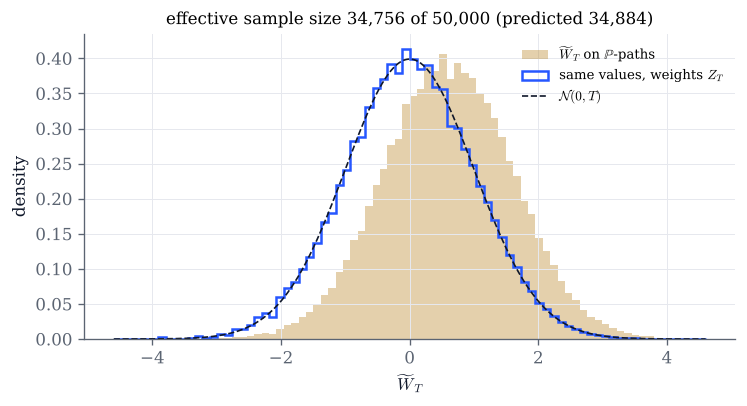

In [2]:
def reweight(theta=0.6, T=1.0, n_paths=50_000, seed=0):
    t, W = brownian_paths(T=T, n_steps=1, n_paths=n_paths, seed=seed)
    Z = girsanov_density(t, W, theta)[:, -1]
    Wt = W[:, -1] + theta * T
    lim = 4 * np.sqrt(T) + abs(theta) * T
    edges = np.linspace(-lim, lim, 81)
    fig, ax = plt.subplots(figsize=(7, 3.3))
    ax.hist(Wt, bins=edges, density=True, color=GOLD, alpha=0.35, label="$\\widetilde W_T$ on $\\mathbb{P}$-paths")
    ax.hist(Wt, bins=edges, weights=Z / Z.sum() / np.diff(edges)[0], histtype="step", color=COBALT, lw=1.5,
            label="same values, weights $Z_T$")
    y = np.linspace(-lim, lim, 400)
    ax.plot(y, np.exp(-y**2 / (2 * T)) / np.sqrt(2 * np.pi * T), color=INK, ls="--", lw=1, label="$\\mathcal{N}(0,T)$")
    ess = effective_sample_size(Z)
    ax.set(xlabel="$\\widetilde W_T$", ylabel="density",
           title=f"effective sample size {ess:,.0f} of {n_paths:,} (predicted {n_paths / density_second_moment(theta, T):,.0f})")
    ax.legend(fontsize=8)
    plt.show()

reweight()

In [3]:
# Explore: push theta up and watch the weighted histogram become ragged as the effective sample size collapses.
interact(reweight,
         theta=FloatSlider(value=0.6, min=-3.0, max=3.0, step=0.1, continuous_update=False, description="θ"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         n_paths=IntSlider(value=50_000, min=1_000, max=200_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 2. The discounted stock is a martingale under $\mathbb Q$ only

Along the same simulated paths, the plain sample mean of $e^{-rt}S_t$ grows like $S_0e^{(\mu-r)t}$: under $\mathbb P$ the
stock beats the money market on average. Weighted by the density $Z_t$ (the density of $\mathbb Q$ on $\mathcal F_t$,
Lemma 11.1), the mean stays at $S_0$ (Proposition 11.7).

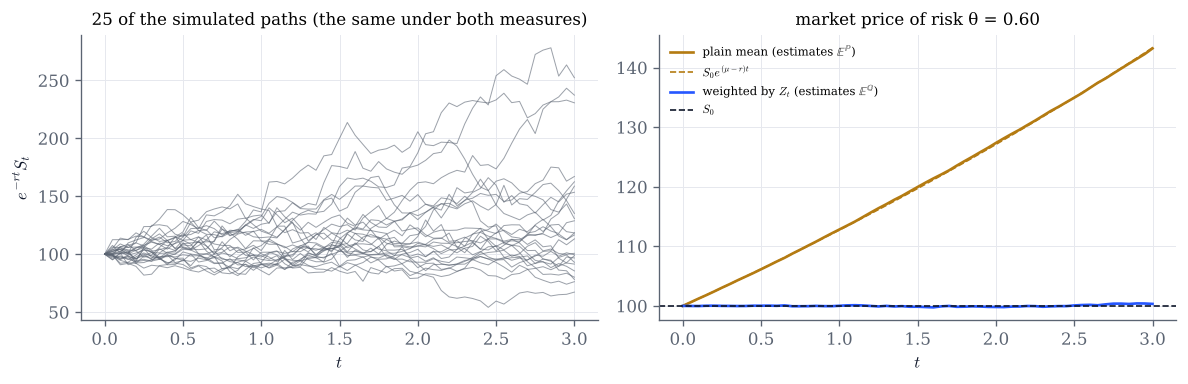

In [4]:
def discounted_stock(mu=0.15, r=0.03, sigma=0.2, T=3.0, n_paths=20_000, seed=1):
    t, W = brownian_paths(T=T, n_steps=60, n_paths=n_paths, seed=seed)
    S = gbm_from_brownian(t, W, 100.0, mu, sigma)
    theta = (mu - r) / sigma
    disc = np.exp(-r * t) * S
    Z = girsanov_density(t, W, theta)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    ax.plot(t, disc[:25].T, color=GREY, lw=0.6, alpha=0.6)
    ax.set(xlabel="$t$", ylabel="$e^{-rt}S_t$", title="25 of the simulated paths (the same under both measures)")
    ax2.plot(t, disc.mean(0), color=GOLD, label="plain mean (estimates $\\mathbb{E}^{\\mathbb{P}}$)")
    ax2.plot(t, 100 * np.exp((mu - r) * t), color=GOLD, ls="--", lw=1, label="$S_0e^{(\\mu-r)t}$")
    ax2.plot(t, (disc * Z).mean(0), color=COBALT, label="weighted by $Z_t$ (estimates $\\mathbb{E}^{\\mathbb{Q}}$)")
    ax2.axhline(100, color=INK, ls="--", lw=1, label="$S_0$")
    ax2.set(xlabel="$t$", title=f"market price of risk θ = {theta:.2f}")
    ax2.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

discounted_stock()

In [5]:
interact(discounted_stock,
         mu=FloatSlider(value=0.15, min=-0.2, max=0.4, step=0.01, continuous_update=False, description="μ"),
         r=FloatSlider(value=0.03, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ"),
         T=FloatSlider(value=3.0, min=0.5, max=10.0, step=0.5, continuous_update=False, description="T"),
         n_paths=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Pricing from real-world paths

The price of a call is $e^{-rT}\mathbb E^{\mathbb Q}[(S_T-K)^+]=\mathbb E^{\mathbb P}[Z_Te^{-rT}(S_T-K)^+]$
(Theorem 11.8). Below, three estimators as the number of paths grows: the weighted average of $\mathbb P$-paths, the
plain average of $\mathbb P$-paths (which estimates $e^{-rT}\mathbb E^{\mathbb P}[(S_T-K)^+]$, not a price), and the
plain average of paths simulated directly under $\mathbb Q$, with drift $r$.

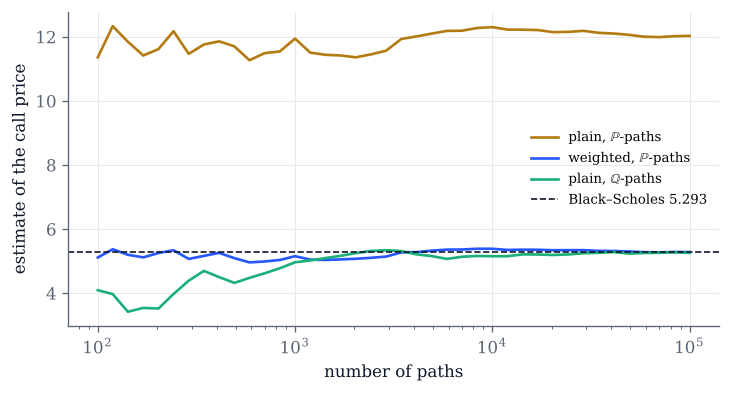

In [6]:
def pricing(mu=0.15, sigma=0.2, K=110.0, r=0.03, T=1.0, seed=2):
    S0, M = 100.0, 100_000
    theta = (mu - r) / sigma
    t, W = brownian_paths(T=T, n_steps=1, n_paths=M, seed=seed)
    ST_P = gbm_from_brownian(T, W[:, -1], S0, mu, sigma)
    Z = girsanov_density(t, W, theta)[:, -1]
    _, W2 = brownian_paths(T=T, n_steps=1, n_paths=M, seed=seed + 1000)
    ST_Q = gbm_from_brownian(T, W2[:, -1], S0, r, sigma)
    disc = np.exp(-r * T)
    m = np.unique(np.logspace(2, 5, 40).astype(int))
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for values, color, label in ((disc * np.maximum(ST_P - K, 0), GOLD, "plain, $\\mathbb{P}$-paths"),
                                 (Z * disc * np.maximum(ST_P - K, 0), COBALT, "weighted, $\\mathbb{P}$-paths"),
                                 (disc * np.maximum(ST_Q - K, 0), "#1BAF7A", "plain, $\\mathbb{Q}$-paths")):
        ax.plot(m, np.cumsum(values)[m - 1] / m, color=color, label=label)
    exact = bs_price(S0, K, T, r, sigma)
    ax.axhline(exact, color=INK, ls="--", lw=1, label=f"Black–Scholes {exact:.3f}")
    ax.set(xscale="log", xlabel="number of paths", ylabel="estimate of the call price")
    ax.legend(fontsize=8)
    plt.show()

pricing()

In [7]:
# Explore: the gold curve moves with mu; the blue and green curves do not.
interact(pricing,
         mu=FloatSlider(value=0.15, min=-0.2, max=0.4, step=0.01, continuous_update=False, description="μ"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ"),
         K=FloatSlider(value=110.0, min=60.0, max=180.0, step=5.0, continuous_update=False, description="K"),
         r=FloatSlider(value=0.03, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         seed=IntSlider(value=2, min=0, max=100, continuous_update=False, description="seed"));

## 4. The stock as numeraire

Under $\mathbb Q^S$, with density $e^{-rT}S_T/S_0$, the stock drifts at $r+\sigma^2$ instead of $r$. The Black–Scholes
formula is $S_0\,\mathbb Q^S(S_T>K)-Ke^{-rT}\mathbb Q(S_T>K)=S_0N(d_+)-Ke^{-rT}N(d_-)$ (Proposition 11.13). Left: the
law of $\log(S_T/S_0)$ under the two measures and the masses to the right of $K$. Right: the call price estimated by
$e^{-rT}(S_T-K)^+$ under $\mathbb Q$ and by $S_0(1-K/S_T)^+$ under $\mathbb Q^S$, from the same normal draws, with
95% confidence bands, and the exact standard deviations of the two estimators in the title.

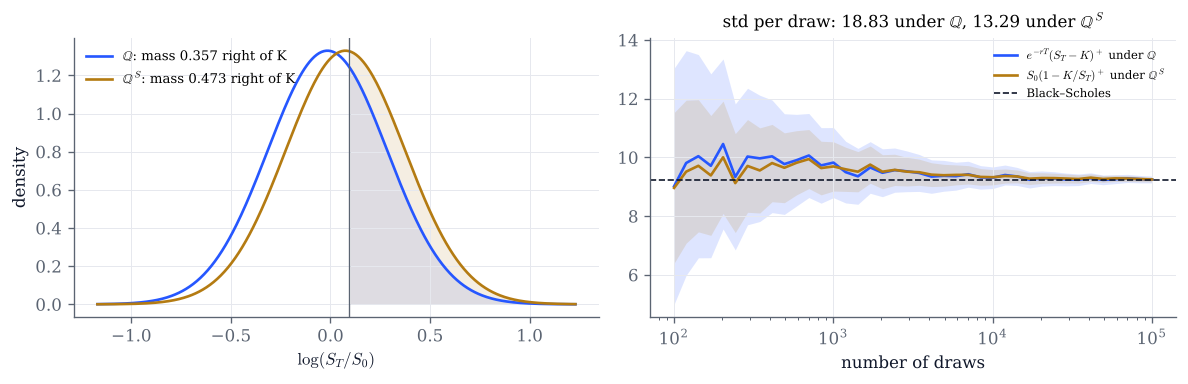

In [8]:
def numeraire(K=110.0, sigma=0.3, r=0.03, T=1.0, seed=3):
    S0 = 100.0
    pQ, pS = exercise_probabilities(S0, K, T, r, sigma)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3))
    y = np.linspace(-4 * sigma * np.sqrt(T), 4 * sigma * np.sqrt(T), 400) + r * T
    k = np.log(K / S0)
    for m, color, name, p in (((r - sigma**2 / 2) * T, COBALT, "$\\mathbb{Q}$", pQ),
                              ((r + sigma**2 / 2) * T, GOLD, "$\\mathbb{Q}^S$", pS)):
        dens = np.exp(-(y - m)**2 / (2 * sigma**2 * T)) / np.sqrt(2 * np.pi * sigma**2 * T)
        ax.plot(y, dens, color=color, label=f"{name}: mass {p:.3f} right of K")
        ax.fill_between(y, 0, dens, where=y > k, color=color, alpha=0.12, lw=0)
    ax.axvline(k, color=GREY, lw=0.8)
    ax.set(xlabel="$\\log(S_T/S_0)$", ylabel="density")
    ax.legend(fontsize=8)

    samples = call_samples_two_numeraires(S0, K, T, r, sigma, 100_000, seed=seed)
    m = np.unique(np.logspace(2, 5, 40).astype(int))
    for name, color, label in (("Q", COBALT, "$e^{-rT}(S_T-K)^+$ under $\\mathbb{Q}$"),
                               ("QS", GOLD, "$S_0(1-K/S_T)^+$ under $\\mathbb{Q}^S$")):
        v = samples[name]
        mean = np.cumsum(v)[m - 1] / m
        sd = np.sqrt(np.maximum(np.cumsum(v**2)[m - 1] / m - mean**2, 0))
        ax2.plot(m, mean, color=color, label=label)
        ax2.fill_between(m, mean - 1.96 * sd / np.sqrt(m), mean + 1.96 * sd / np.sqrt(m), color=color, alpha=0.15, lw=0)
    exact = bs_price(S0, K, T, r, sigma)
    ax2.axhline(exact, color=INK, ls="--", lw=1, label="Black–Scholes")
    std = call_estimator_std(S0, K, T, r, sigma)
    ax2.set(xscale="log", xlabel="number of draws",
            title=rf"std per draw: {std['Q'][0]:.2f} under $\mathbb{{Q}}$, {std['QS'][0]:.2f} under $\mathbb{{Q}}^S$")
    ax2.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

numeraire()

In [9]:
interact(numeraire,
         K=FloatSlider(value=110.0, min=40.0, max=250.0, step=5.0, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.3, min=0.05, max=0.8, step=0.01, continuous_update=False, description="σ"),
         r=FloatSlider(value=0.03, min=-0.02, max=0.1, step=0.005, continuous_update=False, description="r"),
         T=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"),
         seed=IntSlider(value=3, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 1, set $\theta=2.5$ and $T=5$. How many paths does the reweighting effectively keep? Compare with
  $Me^{-\theta^2T}$, and explain why simulating directly under $\mathbb Q$ is preferable when the model allows it.
- In section 2, set $\mu=r$. What are $\theta$ and $Z_t$, and why do the two curves coincide?
- In section 3, find a value of $\mu$ for which the plain average of $\mathbb P$-paths happens to equal the price.
  Is that a coincidence of the strike, or does it hold for every $K$?
- In section 4, move $K$ far into the money and far out of the money. Which estimator wins, and by how much? What
  happens to $S_0(1-K/S_T)^+$ when $K\to0$?